In [1]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


已输出 overlap 基因到: ivf_2c_iDEG_geneid_DPA_overlap.txt (共 32 个)
已保存 SVG 图: ivf_2c_iDEG_geneid_overlap.svg


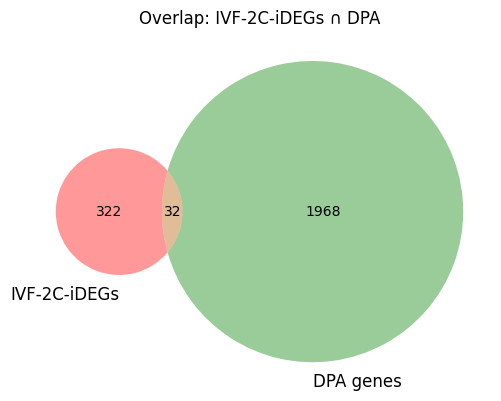

IVF-2C-iDEGs ∩ DPA 交集基因数: 32

已输出 overlap 基因到: pa_2c_iDEG_geneid_DPA_overlap.txt (共 61 个)
已保存 SVG 图: pa_2c_iDEG_geneid_overlap.svg


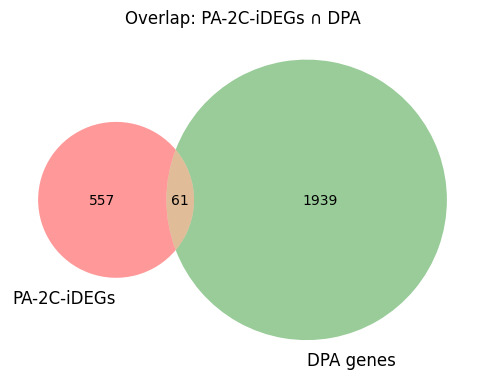

PA-2C-iDEGs ∩ DPA 交集基因数: 61

已输出 overlap 基因到: ivf_4c_iDEG_geneid_DPA_overlap.txt (共 311 个)
已保存 SVG 图: ivf_4c_iDEG_geneid_overlap.svg


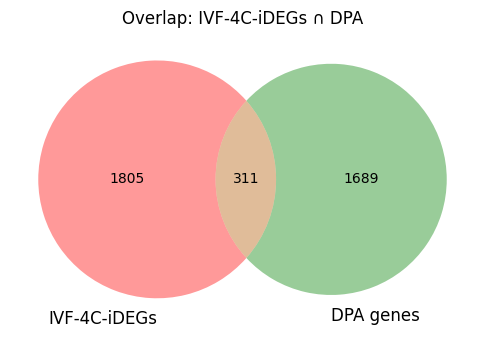

IVF-4C-iDEGs ∩ DPA 交集基因数: 311

已输出 overlap 基因到: pa_4c_iDEG_geneid_DPA_overlap.txt (共 136 个)
已保存 SVG 图: pa_4c_iDEG_geneid_overlap.svg


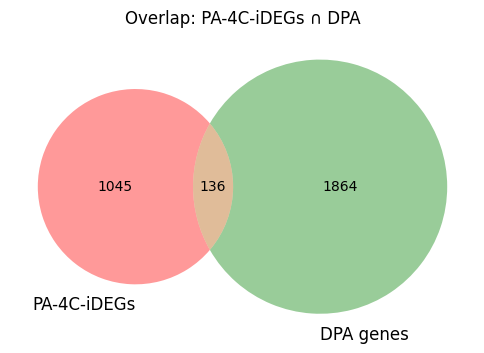

PA-4C-iDEGs ∩ DPA 交集基因数: 136



In [10]:
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
import os

# 设置工作目录
work_dir = "/home/lihaoxing/jupyter"
os.chdir(work_dir)

# 读取 DPA 基因列表
with open("ct2genes_top2000_id.txt", "r") as f:
    dpa = set(line.strip() for line in f if line.strip())

# 文件名到显示标签的映射
label_map = {
    "ivf_2c_iDEG_geneid.txt": "IVF-2C-iDEGs",
    "pa_2c_iDEG_geneid.txt": "PA-2C-iDEGs",
    "ivf_4c_iDEG_geneid.txt": "IVF-4C-iDEGs",
    "pa_4c_iDEG_geneid.txt": "PA-4C-iDEGs"
}

# 按顺序处理四个文件
ideg_files = ["ivf_2c_iDEG_geneid.txt", "pa_2c_iDEG_geneid.txt",
              "ivf_4c_iDEG_geneid.txt", "pa_4c_iDEG_geneid.txt"]

for f in ideg_files:
    # 读取当前 iDEG 列表
    with open(f, "r") as fh:
        ideg = set(line.strip() for line in fh if line.strip())
    
    ideg_label = label_map[f]   # 例如 "IVF-2C-iDEGs"
    
    # 计算交集
    intersect = ideg & dpa
    
    # ---------- 输出 overlap 基因 ID 到新文件 ----------
    base_name = os.path.splitext(f)[0]   # 去掉 .txt
    overlap_file = f"{base_name}_DPA_overlap.txt"
    with open(overlap_file, "w") as out_f:
        for gene in sorted(intersect):   # 排序后输出，便于查看
            out_f.write(gene + "\n")
    print(f"已输出 overlap 基因到: {overlap_file} (共 {len(intersect)} 个)")
    
    # ---------- 绘制韦恩图 ----------
    plt.figure(figsize=(6, 6))
    venn2([ideg, dpa], set_labels=(ideg_label, "DPA genes"))
    plt.title(f"Overlap: {ideg_label} ∩ DPA", fontsize=12)
    
    # 保存为 SVG（矢量格式，透明背景）
    svg_file = f"{base_name}_overlap.svg"
    plt.savefig(svg_file, dpi=300, bbox_inches="tight", transparent=True)
    print(f"已保存 SVG 图: {svg_file}")
    
    # 显示图形（关闭窗口后继续下一个）
    plt.show()
    
    # 控制台也打印交集大小（可选）
    print(f"{ideg_label} ∩ DPA 交集基因数: {len(intersect)}\n")

Red points (Up-regulated genes): 2
Blue points (Down-regulated genes): 2


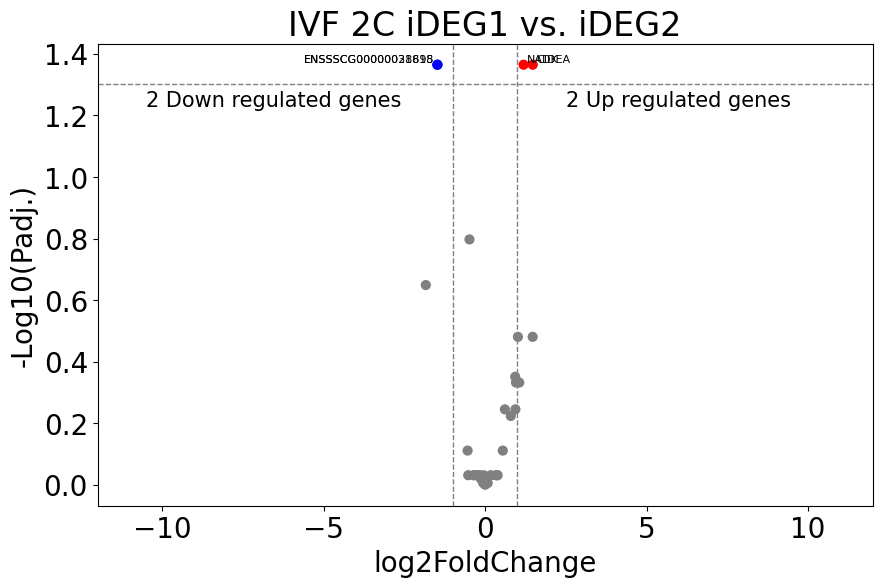

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 读取数据
file_path = 'IVF_2C_iDEG_DPA_overlap_readcounts_DEG.txt'
data = pd.read_csv(file_path, sep='\t')

# 计算 -log10(pvalue)
data['-log10(pvalue)'] = -np.log10(data['padj'].replace(0, np.nan))

# 设置颜色条件
def color_condition(row):
    if row['padj'] >= 0.05:
        return 'grey'
    elif row['padj'] < 0.05 and row['log2FoldChange'] > 1:
        return 'red'
    elif row['padj'] < 0.05 and row['log2FoldChange'] < -1:
        return 'blue'
    else:
        return 'grey'

data['color'] = data.apply(color_condition, axis=1)
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=['log2FoldChange', '-log10(pvalue)'])

plt.rcParams.update({'font.size': 20})

# 绘图
plt.figure(figsize=(10, 6))
plt.scatter(data['log2FoldChange'], data['-log10(pvalue)'], c=data['color'], s=40)

# 辅助线
plt.axhline(y=-np.log10(0.05), color='grey', linestyle='--', linewidth=1)
plt.axvline(x=1, color='grey', linestyle='--', linewidth=1)
plt.axvline(x=-1, color='grey', linestyle='--', linewidth=1)

# 计算最大值用于注释位置
if len(data) > 0 and not data['-log10(pvalue)'].isna().all():
    max_value = max(data['-log10(pvalue)'])
else:
    max_value = 0

# 原有注释（保留）
plt.text(2.5, max_value * 0.9, '2 Up regulated genes', horizontalalignment='left', color='black', fontsize=15)
plt.text(-10.5, max_value * 0.9, '2 Down regulated genes', horizontalalignment='left', color='black', fontsize=15)

plt.title('IVF 2C iDEG1 vs. iDEG2')
plt.xlabel('log2FoldChange')
plt.ylabel('-Log10(Padj.)')
plt.xlim(-12, 12)

# ===================== 新增：标记基因名称 =====================
# 若基因过多，可取消下面注释，只标记 top N（按 -log10(pvalue) 排序）
# top_n = 20
# up_subset = data[(data['padj'] < 0.05) & (data['log2FoldChange'] > 1)].nlargest(top_n, '-log10(pvalue)')
# down_subset = data[(data['padj'] < 0.05) & (data['log2FoldChange'] < -1)].nlargest(top_n, '-log10(pvalue)')

# 全部标记（推荐仅当基因数≤50时使用）
up_subset = data[(data['padj'] < 0.05) & (data['log2FoldChange'] > 1)]
down_subset = data[(data['padj'] < 0.05) & (data['log2FoldChange'] < -1)]

for _, row in up_subset.iterrows():
    plt.text(row['log2FoldChange'] + 0.1, row['-log10(pvalue)'] , row['Gene'],
             fontsize=8, ha='left', va='bottom')

for _, row in down_subset.iterrows():
    plt.text(row['log2FoldChange'] - 0.1, row['-log10(pvalue)'] , row['Gene'],
             fontsize=8, ha='right', va='bottom')
# =============================================================

# 统计红蓝点数（保持不变）
red_points_count = data[data['color'] == 'red'].shape[0]
blue_points_count = data[data['color'] == 'blue'].shape[0]
print(f"Red points (Up-regulated genes): {red_points_count}")
print(f"Blue points (Down-regulated genes): {blue_points_count}")

plt.savefig('IVF_2C_iDEG_DPA_overlap_out.svg', dpi=300, bbox_inches='tight', transparent=True)

# 提取上下调基因（保持不变）
up_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] > 1)]['Gene']
down_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] < -1)]['Gene']
up_genes.to_csv('IVF_2C_iDEG_DPA_overlap_up_genes.txt', index=False, header=False)
down_genes.to_csv('IVF_2C_iDEG_DPA_overlap_down_genes.txt', index=False, header=False)

Red points (Up-regulated genes): 90
Blue points (Down-regulated genes): 52


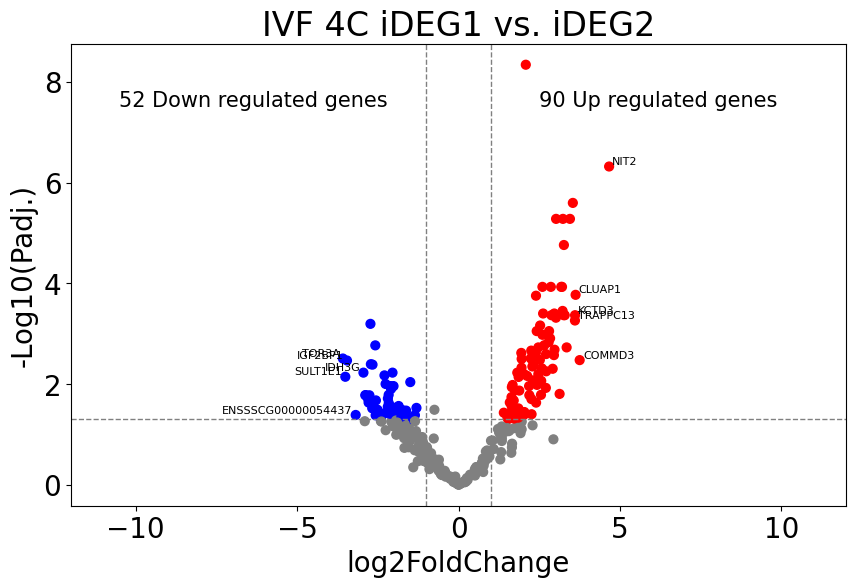

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 读取数据
file_path = 'IVF_4C_iDEG_DPA_overlap_readcounts_DEG.txt'
data = pd.read_csv(file_path, sep='\t')

# 计算 -log10(pvalue)
data['-log10(pvalue)'] = -np.log10(data['padj'].replace(0, np.nan))

# 设置颜色条件
def color_condition(row):
    if row['padj'] >= 0.05:
        return 'grey'
    elif row['padj'] < 0.05 and row['log2FoldChange'] > 1:
        return 'red'
    elif row['padj'] < 0.05 and row['log2FoldChange'] < -1:
        return 'blue'
    else:
        return 'grey'

data['color'] = data.apply(color_condition, axis=1)
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=['log2FoldChange', '-log10(pvalue)'])

plt.rcParams.update({'font.size': 20})

# 绘图
plt.figure(figsize=(10, 6))
plt.scatter(data['log2FoldChange'], data['-log10(pvalue)'], c=data['color'], s=40)

# 辅助线
plt.axhline(y=-np.log10(0.05), color='grey', linestyle='--', linewidth=1)
plt.axvline(x=1, color='grey', linestyle='--', linewidth=1)
plt.axvline(x=-1, color='grey', linestyle='--', linewidth=1)

# 计算最大值用于注释位置
if len(data) > 0 and not data['-log10(pvalue)'].isna().all():
    max_value = max(data['-log10(pvalue)'])
else:
    max_value = 0

# 原有文本注释（数字会自动更新，但您已固定写为90和52，如需动态可改为 f"{red_points_count} Up..."）
plt.text(2.5, max_value * 0.9, '90 Up regulated genes', horizontalalignment='left', color='black', fontsize=15)
plt.text(-10.5, max_value * 0.9, '52 Down regulated genes', horizontalalignment='left', color='black', fontsize=15)

plt.title('IVF 4C iDEG1 vs. iDEG2')
plt.xlabel('log2FoldChange')
plt.ylabel('-Log10(Padj.)')
plt.xlim(-12, 12)

# ===================== 新增：标记 Top5 基因名称 =====================
# 上调：按 log2FoldChange 降序取前5
up_top5 = data[(data['padj'] < 0.05) & (data['log2FoldChange'] > 1)].nlargest(5, 'log2FoldChange')
# 下调：按 log2FoldChange 升序取前5（即最负的5个）
down_top5 = data[(data['padj'] < 0.05) & (data['log2FoldChange'] < -1)].nsmallest(5, 'log2FoldChange')

# 标记上调（红色）基因
for _, row in up_top5.iterrows():
    plt.text(row['log2FoldChange'] + 0.1, row['-log10(pvalue)'], row['Gene'],
             fontsize=8, ha='left', va='bottom', color='black')

# 标记下调（蓝色）基因
for _, row in down_top5.iterrows():
    plt.text(row['log2FoldChange'] - 0.1, row['-log10(pvalue)'], row['Gene'],
             fontsize=8, ha='right', va='bottom', color='black')
# =============================================================

# 统计红蓝点数
red_points_count = data[data['color'] == 'red'].shape[0]
blue_points_count = data[data['color'] == 'blue'].shape[0]
print(f"Red points (Up-regulated genes): {red_points_count}")
print(f"Blue points (Down-regulated genes): {blue_points_count}")

plt.savefig('IVF_4C_iDEG_DPA_overlap_out.svg', dpi=300, bbox_inches='tight', transparent=True)

# 提取上下调基因（保持不变）
up_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] > 1)]['Gene']
down_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] < -1)]['Gene']
up_genes.to_csv('IVF_4C_iDEG_DPA_overlap_up_genes.txt', index=False, header=False)
down_genes.to_csv('IVF_4C_iDEG_DPA_overlap_down_genes.txt', index=False, header=False)